# Textbook slack baseline, end to end (tier S)

This notebook implements the formulation in the doc *Textbook slack formulation — Pasqal CVRP clustering baseline*
on one tier S instance (N = 4 customers, K = 2 trucks, Q = 7), and runs every stage so you can see what each one does:

| Stage | What happens | Check |
|---|---|---|
| 1. Instance | seeded generator, feasibility certificate | brute force over all K^N assignments |
| 2. Constrained model | objective f(x), C1 (one truck per customer), C2 (load ≤ Q) | brute-force optimum = reference C* |
| 3. Slack QUBO | x (NK bits) + y (K·B slack bits) → matrix Qmat | brute force all 2^14 bitstrings: argmin = C*? |
| 4. Embedding | atom positions so C6/r^6 ≈ α·J, detuning ≈ −α·h | embedding error, and brute force of the *embedded* energy |
| 5. Pulse + emulation | adiabatic sweep on `AnalogDevice`, emulated exactly with emu-sv | shot histogram |
| 6. Decode + metrics | drop y, check C1/C2 on x, gaps (Section 9 of the brief) | vs. uniform random sampler |
| 7. Close the loop | route each cluster exactly, CVRP gap | brute-force CVRP reference |

Two variants run side by side in stages 4–6: **global detuning only** (what the QPU allows) and **global + DMM**
(emulator only, lets each atom get its own linear term).

In [1]:
import itertools
import dataclasses
from collections import Counter

import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize

from pulser import Sequence, Pulse
from pulser.devices import AnalogDevice, MockDevice
from pulser.register.register_layout import RegisterLayout
from pulser.waveforms import InterpolatedWaveform, RampWaveform
import emu_sv
import torch

plt.rcParams.update({"figure.dpi": 110, "axes.grid": False})
SEED = 7
DEVICE = AnalogDevice
C6 = DEVICE.interaction_coeff          # rad/us * um^6
R_MIN = DEVICE.min_atom_distance       # um
R_MAX = DEVICE.max_radial_distance     # um
OMEGA_MAX = DEVICE.channels["rydberg_global"].max_amp
DELTA_MAX = DEVICE.channels["rydberg_global"].max_abs_detuning
print(f"C6={C6:.0f}  r_min={R_MIN} um  R_max={R_MAX} um  Omega_max={OMEGA_MAX:.2f}  |delta|_max={DELTA_MAX:.2f} rad/us")
print(f"strongest possible coupling C6/r_min^6 = {C6 / R_MIN**6:.1f} rad/us")

C6=865723  r_min=5 um  R_max=38 um  Omega_max=12.57  |delta|_max=125.66 rad/us
strongest possible coupling C6/r_min^6 = 55.4 rad/us


## 1. Instance (Task A2)

Tier S: N = 4, K = 2, Q = 7, demands in {1..4}, locations in a 100 × 100 square, depot fixed at the centre.
We keep drawing seeds until the instance is **feasible** *and* the **capacity constraint is active**
(the distance-optimal split ignoring C2 overloads a truck). Otherwise the slack bits would have nothing to do
and the test would be meaningless.

In [2]:
N, K, Q, DEMAND_RANGE = 4, 2, 7, (1, 4)
DEPOT = np.array([50.0, 50.0])


def make_instance(seed):
    rng = np.random.default_rng(seed)
    xy = rng.uniform(0, 100, size=(N, 2))
    d = rng.integers(DEMAND_RANGE[0], DEMAND_RANGE[1] + 1, size=N)
    return xy, d


def all_assignments():
    """Every customer->truck map as an int array of shape (K**N, N)."""
    return np.array(list(itertools.product(range(K), repeat=N)))


def loads(assign, d):
    return np.array([d[assign == k].sum() for k in range(K)])


def cluster_cost(assign, c):
    """f(x) = sum_k sum_{i<j} c_ij x_ik x_jk  (total pairwise distance inside clusters)."""
    same = assign[:, None] == assign[None, :]
    return np.triu(c * same, 1).sum()


def is_active(xy, d):
    c = np.linalg.norm(xy[:, None] - xy[None, :], axis=-1)
    A_ = all_assignments()
    f = np.array([cluster_cost(a, c) for a in A_])
    feas = np.array([loads(a, d).max() <= Q for a in A_])
    return feas.any() and f[feas].min() > f.min() + 1e-9


seed = SEED
while not is_active(*make_instance(seed)):
    seed += 1
xy, d = make_instance(seed)
c = np.linalg.norm(xy[:, None] - xy[None, :], axis=-1)
rho = d.sum() / (K * Q)
print(f"seed={seed}  demands={d.tolist()}  total={d.sum()}  load ratio rho={rho:.2f}  d_max/Q={d.max() / Q:.2f}")

ASSIGN = all_assignments()
F_ALL = np.array([cluster_cost(a, c) for a in ASSIGN])
FEAS_ALL = np.array([loads(a, d).max() <= Q for a in ASSIGN])
certificate = ASSIGN[FEAS_ALL][0]
assert loads(certificate, d).max() <= Q
print(f"feasibility certificate (customer -> truck): {certificate.tolist()}  loads={loads(certificate, d).tolist()}")


def canon(assign):
    """Vehicles are identical (Pitfall 9.3): a clustering = a set of customer groups."""
    return frozenset(frozenset(np.flatnonzero(assign == k).tolist()) for k in range(K) if (assign == k).any())

seed=12  demands=[1, 4, 2, 4]  total=11  load ratio rho=0.79  d_max/Q=0.57
feasibility certificate (customer -> truck): [0, 0, 0, 1]  loads=[7, 4]


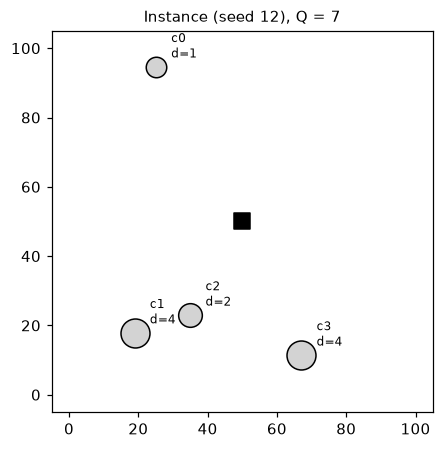

In [3]:
def draw_clusters(ax, assign=None, title="", routes=None):
    ax.scatter(*DEPOT, marker="s", s=120, c="k", zorder=3, label="depot")
    colors = plt.cm.tab10.colors
    for i, (p, di) in enumerate(zip(xy, d)):
        col = "lightgray" if assign is None else colors[assign[i]]
        ax.scatter(*p, s=120 + 60 * di, color=col, edgecolor="k", zorder=3)
        ax.annotate(f"c{i}\nd={di}", p, textcoords="offset points", xytext=(10, 6), fontsize=8)
    if routes is not None:
        for k, r in enumerate(routes):
            if len(r) == 0:
                continue
            path = np.vstack([DEPOT, xy[list(r)], DEPOT])
            ax.plot(*path.T, "-", color=colors[k], lw=1.5, zorder=2)
    ax.set_xlim(-5, 105); ax.set_ylim(-5, 105); ax.set_aspect("equal")
    ax.set_title(title, fontsize=10)


fig, ax = plt.subplots(figsize=(4.5, 4.5))
draw_clusters(ax, title=f"Instance (seed {seed}), Q = {Q}")
plt.show()

## 2. The constrained model and its reference optimum

$f(x)=\sum_k\sum_{i<j} c_{ij}x_{ik}x_{jk}$, subject to (C1) $\sum_k x_{ik}=1$ and (C2) $\sum_i d_i x_{ik}\le Q$.

Tier S has only $K^N = 16$ assignments, so we enumerate them all. The minimum over feasible ones is the
**proven optimum** $C^*$ of the clustering model (reference status: brute force).

C* (clustering model) = 110.01, distinct optimal clusterings = 1: [[[0, 3], [1, 2]]]
ignoring C2, the best split costs 99.47 but loads [1, 10] > Q=7


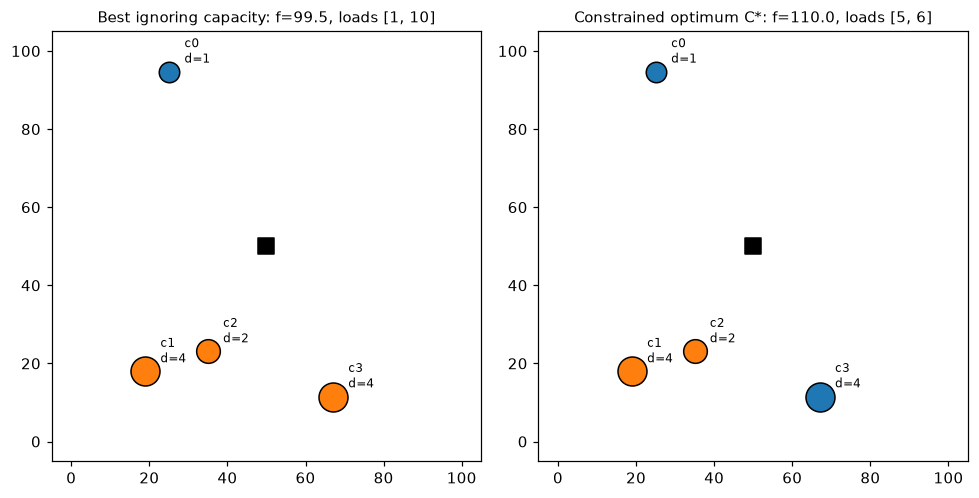

In [4]:
f_star = F_ALL[FEAS_ALL].min()
opt_clusterings = {canon(a) for a, f, ok in zip(ASSIGN, F_ALL, FEAS_ALL) if ok and np.isclose(f, f_star)}
best_unconstrained = ASSIGN[np.argmin(F_ALL)]
print(f"C* (clustering model) = {f_star:.2f}, distinct optimal clusterings = {len(opt_clusterings)}: "
      f"{[sorted(map(sorted, s)) for s in opt_clusterings]}")
print(f"ignoring C2, the best split costs {F_ALL.min():.2f} but loads {loads(best_unconstrained, d).tolist()} > Q={Q}")

fig, axes = plt.subplots(1, 2, figsize=(9, 4.5))
draw_clusters(axes[0], best_unconstrained, f"Best ignoring capacity: f={F_ALL.min():.1f}, "
              f"loads {loads(best_unconstrained, d).tolist()}")
x_star_assign = next(a for a, f, ok in zip(ASSIGN, F_ALL, FEAS_ALL) if ok and np.isclose(f, f_star))
draw_clusters(axes[1], x_star_assign, f"Constrained optimum C*: f={f_star:.1f}, loads {loads(x_star_assign, d).tolist()}")
plt.tight_layout(); plt.show()

## 3. The slack QUBO

$$H(x,y)=\sum_k\sum_{i<j}c_{ij}x_{ik}x_{jk}+A\sum_i\Big(\sum_k x_{ik}-1\Big)^2+W\sum_k\Big(\sum_i d_ix_{ik}+\sum_b w_by_{kb}-Q\Big)^2$$

Slack bits per truck: $B=\lceil\log_2(Q+1)\rceil$, weights $1,2,4,\dots$ with the last one capped so they sum to Q.

**Choosing A and W.** Both penalties are squares of integers, so any violated constraint costs at least A or W.
Every infeasible bitstring therefore has energy ≥ min(A, W), and the feasible optimum has energy $C^*$.
Taking $A, W > f(\text{certificate}) \ge C^*$ guarantees the QUBO ground state is a constrained optimum.
This uses only the certificate, not $C^*$ itself, so it is legitimate on instances we cannot brute-force.
(The doc's per-customer bound $\max_i\sum_j c_{ij}$ is another valid choice; this one is often smaller.)

Variable order (= atom order): `x[k*N + i]` for truck k, customer i; then `y[N*K + k*B + b]`.

In [5]:
B = int(np.ceil(np.log2(Q + 1)))
w = [2 ** b for b in range(B - 1)]
w.append(Q - sum(w))
w = np.array(w)
assert w.sum() == Q and set(range(Q + 1)) <= {int(np.dot(bits, w)) for bits in itertools.product([0, 1], repeat=B)}
n_x, n_y = N * K, K * B
n = n_x + n_y


def xi(i, k):
    return k * N + i


def yi(k, b):
    return n_x + k * B + b


labels = [f"x{i},{k}" for k in range(K) for i in range(N)] + [f"y{k},{b}" for k in range(K) for b in range(B)]


def build_qubo(A, W):
    """Upper-triangular Qmat with E(z) = z^T Qmat z + const (diagonal = linear terms since z^2 = z)."""
    Qm = np.zeros((n, n))
    const = 0.0

    def add(a, b, v):
        Qm[min(a, b), max(a, b)] += v

    for k in range(K):                                  # objective
        for i, j in itertools.combinations(range(N), 2):
            add(xi(i, k), xi(j, k), c[i, j])
    for i in range(N):                                  # C1: A (sum_k x_ik - 1)^2
        for k in range(K):
            add(xi(i, k), xi(i, k), -A)
        for k, l in itertools.combinations(range(K), 2):
            add(xi(i, k), xi(i, l), 2 * A)
        const += A
    for k in range(K):                                  # C2: W (sum_m a_m z_m - Q)^2
        terms = [(xi(i, k), d[i]) for i in range(N)] + [(yi(k, b), w[b]) for b in range(B)]
        for idx, a in terms:
            add(idx, idx, W * (a * a - 2 * Q * a))
        for (p, a), (q, bb) in itertools.combinations(terms, 2):
            add(p, q, 2 * W * a * bb)
        const += W * Q * Q
    return Qm, const


A_pen = W_pen = float(np.ceil(cluster_cost(certificate, c) + 1))
Qmat, const = build_qubo(A_pen, W_pen)
h = np.diag(Qmat).copy()
J = np.triu(Qmat, 1)
J = J + J.T
print(f"A = W = {A_pen:.0f}   atoms n = NK + K*B = {n_x} + {n_y} = {n}   slack weights w = {w.tolist()}")
print(f"non-zero couplings: {int((np.triu(J, 1) > 0).sum())} of {n * (n - 1) // 2} pairs; all >= 0: {bool((J >= 0).all())}")
print(f"linear terms h: x in [{h[:n_x].min():.0f}, {h[:n_x].max():.0f}], y in [{h[n_x:].min():.0f}, {h[n_x:].max():.0f}]")

A = W = 168   atoms n = NK + K*B = 8 + 6 = 14   slack weights w = [1, 2, 4]
non-zero couplings: 46 of 91 pairs; all >= 0: True
linear terms h: x in [-6888, -2352], y in [-6720, -2184]


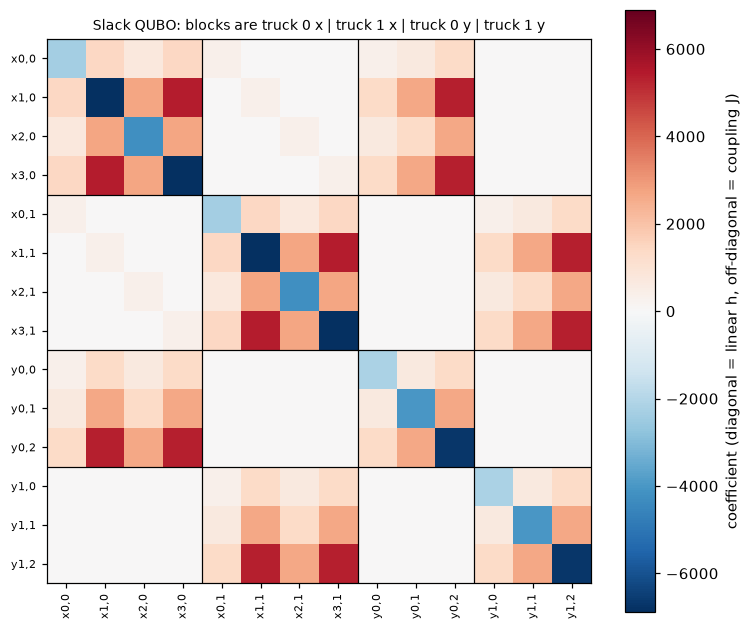

In [6]:
fig, ax = plt.subplots(figsize=(7, 6))
M = J + np.diag(h)
vmax = np.abs(M).max()
im = ax.imshow(M, cmap="RdBu_r", vmin=-vmax, vmax=vmax)
ax.set_xticks(range(n), labels, rotation=90, fontsize=7); ax.set_yticks(range(n), labels, fontsize=7)
for p in [N, n_x, n_x + B]:
    ax.axhline(p - 0.5, c="k", lw=0.8); ax.axvline(p - 0.5, c="k", lw=0.8)
plt.colorbar(im, label="coefficient (diagonal = linear h, off-diagonal = coupling J)")
ax.set_title("Slack QUBO: blocks are truck 0 x | truck 1 x | truck 0 y | truck 1 y", fontsize=9)
plt.tight_layout(); plt.show()

### Brute-force the QUBO (2^14 = 16 384 bitstrings)

The real test of the formulation: is the lowest-energy bitstring a constrained optimum?
We also count how many bitstrings correspond to *feasible clusterings* and how many of those have the slack bits exactly right
(energy = f(x)), i.e. the 2^(KB) blow-up of the search space.

QUBO ground state: E=110.01 (C* = 110.01), C1=True, C2=True, clustering=[[0, 3], [1, 2]], optimal=True


bitstrings: 16384; decode to feasible clustering: 512 (3.1%); of those with slack exactly right: 8


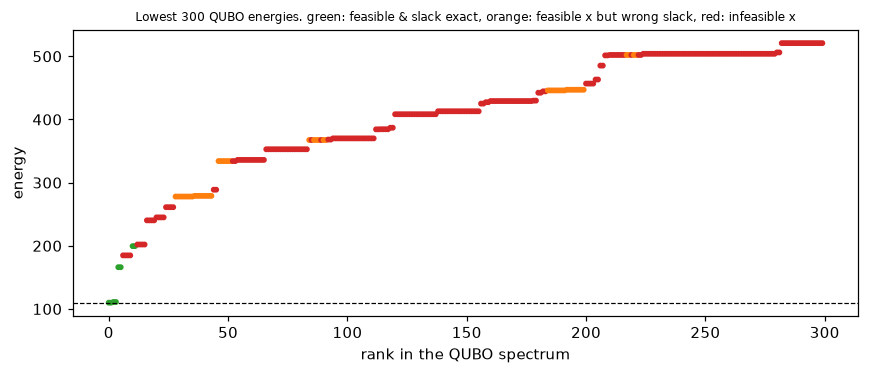

In [7]:
Z = ((np.arange(2 ** n)[:, None] >> np.arange(n)[::-1]) & 1).astype(np.int8)   # row r = bitstring, MSB = atom 0


def energies(Z, h, J):
    Zf = Z.astype(float)
    return Zf @ h + 0.5 * np.einsum("ri,ij,rj->r", Zf, J, Zf)


def decode(z):
    """Drop slack bits; return (assignment or None if C1 broken, C1 ok, C2 ok on x alone)."""
    X = np.asarray(z[:n_x]).reshape(K, N)            # X[k, i]
    c1 = bool((X.sum(0) == 1).all())
    if not c1:
        return None, False, False
    assign = X.argmax(0)
    return assign, True, bool(loads(assign, d).max() <= Q)


E = energies(Z, h, J) + const
order = np.argsort(E)
z0 = Z[order[0]]
a0, c1_ok, c2_ok = decode(z0)
print(f"QUBO ground state: E={E[order[0]]:.2f} (C* = {f_star:.2f}), C1={c1_ok}, C2={c2_ok}, "
      f"clustering={sorted(map(sorted, canon(a0)))}, optimal={canon(a0) in opt_clusterings}")

dec = [decode(z) for z in Z]
feas_mask = np.array([ok1 and ok2 for _, ok1, ok2 in dec])
x_feas_y_exact = feas_mask & np.isclose(E, [cluster_cost(a, c) if a is not None else np.nan for a, *_ in dec])
print(f"bitstrings: {2 ** n}; decode to feasible clustering: {feas_mask.sum()} ({feas_mask.mean():.1%}); "
      f"of those with slack exactly right: {x_feas_y_exact.sum()}")

fig, ax = plt.subplots(figsize=(8, 3.5))
top = order[:300]
cols = np.where(x_feas_y_exact[top], "tab:green", np.where(feas_mask[top], "tab:orange", "tab:red"))
ax.scatter(np.arange(len(top)), E[top], c=cols, s=8)
ax.axhline(f_star, ls="--", c="k", lw=0.8)
ax.set_xlabel("rank in the QUBO spectrum"); ax.set_ylabel("energy")
ax.set_title("Lowest 300 QUBO energies. green: feasible & slack exact, orange: feasible x but wrong slack, red: infeasible x",
             fontsize=8)
plt.tight_layout(); plt.show()

### How small can A and W be?
Smaller penalties leave more of the device's energy range for the objective. The scan brute-forces the QUBO for
each (A, W) and marks whether the ground state decodes to a constrained optimum. The chosen point is the star.

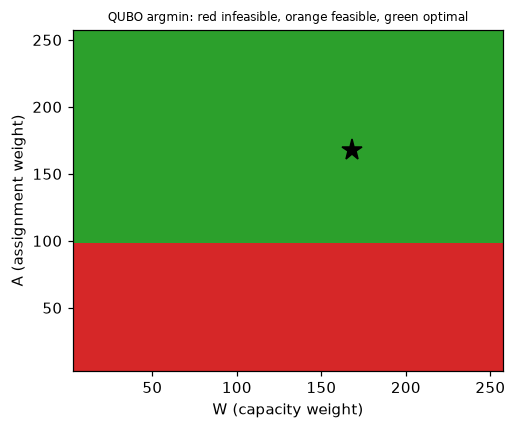

In [8]:
grid = np.linspace(0.05, 1.5, 24) * A_pen
ok = np.zeros((len(grid), len(grid)), dtype=int)   # 0 infeasible, 1 feasible not optimal, 2 optimal
for a_i, A_ in enumerate(grid):
    for w_i, W_ in enumerate(grid):
        Qm_, k_ = build_qubo(A_, W_)
        h_, J_ = np.diag(Qm_), np.triu(Qm_, 1) + np.triu(Qm_, 1).T
        assign_, ok1, ok2 = decode(Z[np.argmin(energies(Z, h_, J_))])
        ok[a_i, w_i] = 0 if not (ok1 and ok2) else (2 if canon(assign_) in opt_clusterings else 1)
fig, ax = plt.subplots(figsize=(4.8, 4))
ax.pcolormesh(grid, grid, ok, cmap=plt.matplotlib.colors.ListedColormap(["tab:red", "tab:orange", "tab:green"]),
              vmin=0, vmax=2)
ax.plot(W_pen, A_pen, "k*", ms=14)
ax.set_xlabel("W (capacity weight)"); ax.set_ylabel("A (assignment weight)")
ax.set_title("QUBO argmin: red infeasible, orange feasible, green optimal", fontsize=8)
plt.tight_layout(); plt.show()

## 4. Embedding: atom positions and detuning

At the end of the sweep (Ω = 0) the device energy is $\sum_{m<n} U_{mn} n_m n_n - \sum_m \delta_m n_m$ with
$U_{mn}=C_6/r_{mn}^6$. We want $U \approx \alpha J$ and $-\delta_m \approx \alpha h_m$ for one scale α > 0.

* **Couplings.** Optimise the 2n coordinates to minimise the relative error $\|U-\alpha J\|_F/\|\alpha J\|_F$
  (α solved in closed form each step), with penalties for $r<5\,\mu m$ and radius $>38\,\mu m$. Many random restarts.
  Pairs with J = 0 still count: their wanted coupling is 0, so the fit pushes them apart.
* **Linear terms, global only.** One δ for every atom: the least-squares choice is $\delta=-\alpha\,\overline{h}$.
* **Linear terms, global + DMM** (emulator only). $\delta_m=\delta+\varepsilon_m\delta_{DMM}$ with
  $\varepsilon_m\in[0,1]$, $\delta_{DMM}\le0$. Set $\delta=-\alpha\min h$ (the largest reward) and
  $\varepsilon_m=(h_m-\min h)/(\max h-\min h)$, $\delta_{DMM}=-\alpha(\max h-\min h)$: exact.

In [9]:
iu = np.triu_indices(n, 1)
J_pairs = J[iu]


def realized_U(P):
    D = np.linalg.norm(P[:, None] - P[None, :], axis=-1)
    return C6 / D[iu] ** 6, D


def embed_loss(flat):
    P = flat.reshape(n, 2)
    U, D = realized_U(P)
    alpha = U @ J_pairs / (J_pairs @ J_pairs)
    rel = np.linalg.norm(U - alpha * J_pairs) / np.linalg.norm(alpha * J_pairs)
    too_close = np.clip(R_MIN * 1.001 - D[iu], 0, None)
    too_far = np.clip(np.linalg.norm(P - P.mean(0), axis=1) - R_MAX * 0.999, 0, None)
    return rel + 50 * (too_close ** 2).sum() + 50 * (too_far ** 2).sum()


rng = np.random.default_rng(0)
best = None
for restart in range(60):
    P0 = rng.uniform(-10, 10, size=(n, 2))
    res = minimize(embed_loss, P0.ravel(), method="L-BFGS-B", options={"maxiter": 3000})
    if best is None or res.fun < best.fun:
        best = res
pos = best.x.reshape(n, 2)
pos -= pos.mean(0)
pos *= max(1.0, (R_MIN + 1e-3) / realized_U(pos)[1][iu].min())   # soft penalty -> hard: stretch if any pair < r_min
U_pairs, Dm = realized_U(pos)
alpha = U_pairs @ J_pairs / (J_pairs @ J_pairs)
emb_err = np.linalg.norm(U_pairs - alpha * J_pairs) / np.linalg.norm(alpha * J_pairs)
print(f"alpha = {alpha:.4g} (rad/us per QUBO unit)   coupling error ||U - aJ||/||aJ|| = {emb_err:.1%}")
print(f"min distance {Dm[iu].min():.2f} um (>= {R_MIN}), max radius {np.linalg.norm(pos, axis=1).max():.2f} um (<= {R_MAX})")
assert Dm[iu].min() >= R_MIN - 1e-6 and np.linalg.norm(pos, axis=1).max() <= R_MAX + 1e-6

U = np.zeros((n, n)); U[iu] = U_pairs; U = U + U.T
delta_glob = -alpha * h.mean()
delta_dmm_top = -alpha * h.min()
eps = (h - h.min()) / (h.max() - h.min())
delta_dmm = -alpha * (h.max() - h.min())
h_glob = np.full(n, -delta_glob) / alpha       # realized linear terms, mapped back to QUBO units
h_dmm = -(delta_dmm_top + eps * delta_dmm) / alpha
print(f"global only: delta_final = {delta_glob:.2f} rad/us, linear-term error ||h_real - h||/||h|| = "
      f"{np.linalg.norm(h_glob - h) / np.linalg.norm(h):.1%}")
print(f"global+DMM: delta_final = {delta_dmm_top:.2f}, delta_DMM = {delta_dmm:.2f} rad/us, eps in [0,1], "
      f"linear-term error {np.linalg.norm(h_dmm - h) / np.linalg.norm(h):.1e}")
assert abs(delta_glob) <= DELTA_MAX and abs(delta_dmm_top) <= DELTA_MAX

def pair_kind(a, b):
    xa, xb = a < n_x, b < n_x
    if xa and xb:
        return "x-x same truck (c + 2W d d)" if a // N == b // N else (
            "x-x same customer (2A)" if a % N == b % N else "x-x unrelated (0)")
    if xa != xb:
        xv, yv = (a, b) if xa else (b, a)
        return "x-y same truck (2W d w)" if xv // N == (yv - n_x) // B else "x-y other truck (0)"
    return "y-y same truck (2W w w)" if (a - n_x) // B == (b - n_x) // B else "y-y other truck (0)"


kinds = np.array([pair_kind(a, b) for a, b in zip(*iu)])
print(f"\n{'pair type':30s}{'pairs':>6s}{'median wanted':>15s}{'median realized':>17s}  (rad/us)")
for kind in sorted(set(kinds)):
    m = kinds == kind
    print(f"{kind:30s}{m.sum():6d}{np.median(alpha * J_pairs[m]):15.3g}{np.median(U_pairs[m]):17.3g}")

f_second = np.unique(np.round(F_ALL[FEAS_ALL], 9))[1]
print(f"\nenergy scales on the device (rad/us): objective gap C*->next feasible = {alpha * (f_second - f_star):.3f}, "
      f"min penalty = {alpha * min(A_pen, W_pen):.2f}, largest coupling = {alpha * J.max():.1f}, "
      f"Omega_max = {OMEGA_MAX:.1f}")

alpha = 0.00282 (rad/us per QUBO unit)   coupling error ||U - aJ||/||aJ|| = 48.8%
min distance 5.97 um (>= 5), max radius 31.69 um (<= 38)
global only: delta_final = 13.40 rad/us, linear-term error ||h_real - h||/||h|| = 37.7%
global+DMM: delta_final = 19.42, delta_DMM = -13.26 rad/us, eps in [0,1], linear-term error 1.1e-16

pair type                      pairs  median wanted  median realized  (rad/us)
x-x same customer (2A)             4          0.947          0.00158
x-x same truck (c + 2W d d)       12           5.84             5.04
x-x unrelated (0)                 12              0          0.00148
x-y other truck (0)               24              0          0.00126
x-y same truck (2W d w)           24           3.79            0.404
y-y other truck (0)                9              0           0.0016
y-y same truck (2W w w)            6           3.79             2.38

energy scales on the device (rad/us): objective gap C*->next feasible = 0.003, min penalty = 0.47, largest co

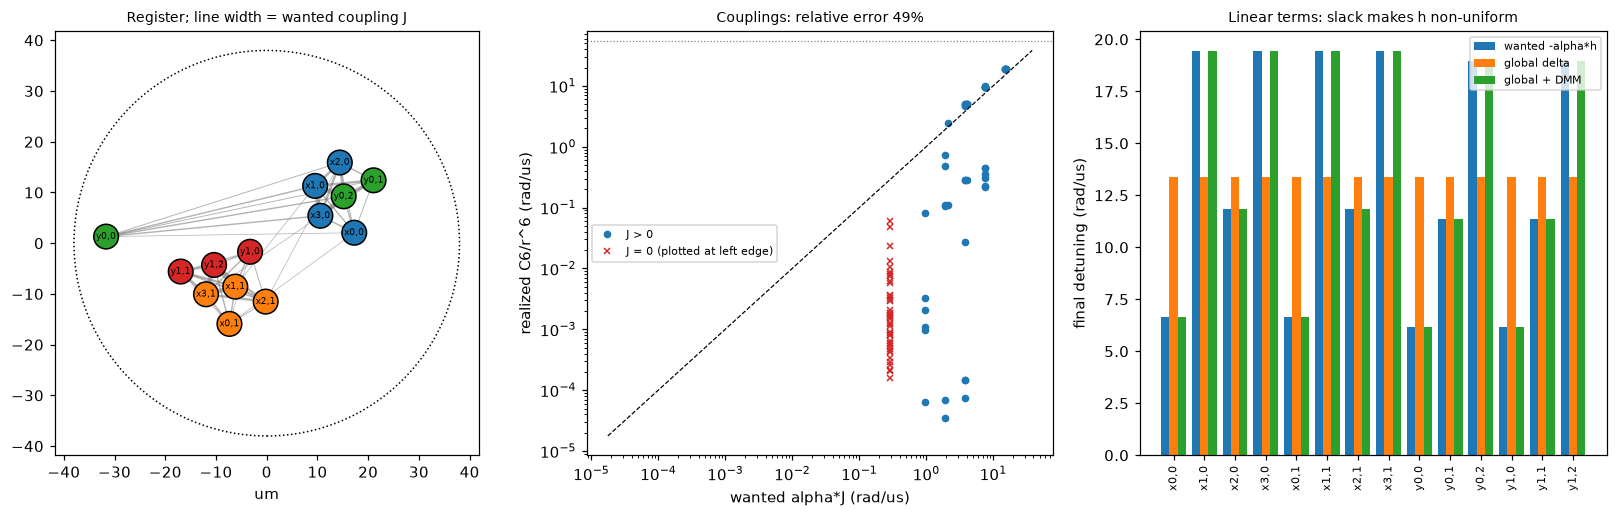

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.8))
ax = axes[0]
for (a, b), Jv in zip(zip(*iu), J_pairs):
    if Jv > 0:
        ax.plot(*pos[[a, b]].T, "-", c="gray", lw=0.3 + 2.5 * Jv / J_pairs.max(), alpha=0.6, zorder=1)
col = ["tab:blue" if m < N else "tab:orange" if m < n_x else "tab:green" if m < n_x + B else "tab:red" for m in range(n)]
ax.scatter(*pos.T, s=260, c=col, edgecolor="k", zorder=2)
for m, p in enumerate(pos):
    ax.annotate(labels[m], p, ha="center", va="center", fontsize=6, zorder=3)
ax.add_patch(plt.Circle((0, 0), R_MAX, fill=False, ls=":", ec="k"))
ax.set_aspect("equal"); ax.set_xlabel("um"); ax.set_title("Register; line width = wanted coupling J", fontsize=9)

ax = axes[1]
nz = J_pairs > 0
ax.loglog(alpha * J_pairs[nz], U_pairs[nz], "o", ms=4, label="J > 0")
ax.loglog(np.full((~nz).sum(), alpha * J_pairs[nz].min() * 0.3), U_pairs[~nz], "x", c="tab:red", ms=4,
          label="J = 0 (plotted at left edge)")
lims = [min(U_pairs.min(), alpha * J_pairs[nz].min()) * 0.5, max(U_pairs.max(), alpha * J_pairs.max()) * 2]
ax.plot(lims, lims, "k--", lw=0.8)
ax.axhline(C6 / R_MIN ** 6, c="gray", ls=":", lw=0.8)
ax.set_xlabel("wanted alpha*J (rad/us)"); ax.set_ylabel("realized C6/r^6 (rad/us)")
ax.set_title(f"Couplings: relative error {emb_err:.0%}", fontsize=9); ax.legend(fontsize=7)

ax = axes[2]
xs = np.arange(n)
ax.bar(xs - 0.27, -alpha * h, 0.27, label="wanted -alpha*h")
ax.bar(xs, np.full(n, delta_glob), 0.27, label="global delta")
ax.bar(xs + 0.27, delta_dmm_top + eps * delta_dmm, 0.27, label="global + DMM")
ax.set_xticks(xs, labels, rotation=90, fontsize=7); ax.set_ylabel("final detuning (rad/us)")
ax.set_title("Linear terms: slack makes h non-uniform", fontsize=9); ax.legend(fontsize=7)
plt.tight_layout(); plt.show()

### Did the embedding keep the answer?
Brute-force the **embedded** final energy (realized couplings + realized detuning) over all 2^14 bitstrings and decode
its ground state. If this is wrong, no pulse can fix it: a perfectly adiabatic sweep would return the wrong answer.
We also report where the true optimum sits in each embedded spectrum.

In [11]:
x_star_bits = [z_idx for z_idx in order if x_feas_y_exact[z_idx] and canon(dec[z_idx][0]) in opt_clusterings][0]
variants = {"intended QUBO": (h, J), "embedded, global": (h_glob, U / alpha), "embedded, global+DMM": (h_dmm, U / alpha)}
spectra = {}
for name, (h_v, J_v) in variants.items():
    E_v = energies(Z, h_v, J_v)
    spectra[name] = E_v
    g = np.argmin(E_v)
    a_v, ok1, ok2 = decode(Z[g])
    rank = int((E_v < E_v[x_star_bits]).sum())
    groups = str(sorted(map(sorted, canon(a_v)))) if a_v is not None else "-"
    print(f"{name:22s} ground state: C1={ok1!s:5} C2={ok2!s:5} clustering={groups:24s} "
          f"optimal={ok1 and ok2 and canon(a_v) in opt_clusterings!s:5}  rank of true optimum = {rank}")

intended QUBO          ground state: C1=True  C2=True  clustering=[[0, 3], [1, 2]]         optimal=True   rank of true optimum = 0
embedded, global       ground state: C1=False C2=False clustering=-                        optimal=False  rank of true optimum = 4410
embedded, global+DMM   ground state: C1=False C2=False clustering=-                        optimal=False  rank of true optimum = 4944


## 5. Pulse and emulation

Standard adiabatic recipe (brief §8.2): amplitude 0 → Ω_max → 0 (smooth interpolation), detuning swept from
δ₀ < 0 (ground state |gg…g⟩) to the final value from stage 4. For the DMM variant the local detuning is ramped
from 0 to δ_DMM over the same window. Register is a layout of 2n traps (AnalogDevice fills at most half of a
layout); the extra traps are far away and empty.

Emulated exactly with **emu-sv** (state vector, 14 atoms → 16 384 amplitudes, no noise).

A third run, **ideal J + DMM**, is a diagnostic, not a device result: it reuses the DMM sequence but tells emu-sv to
replace $C_6/r^6$ by exactly $\alpha J$ (`interaction_matrix=`). It answers "if the embedding were perfect, would this
sweep find the optimum?", which separates embedding failure from pulse (adiabaticity) failure.
For each run we also report how often a shot lands on the ground state of *that run's own* final Hamiltonian.

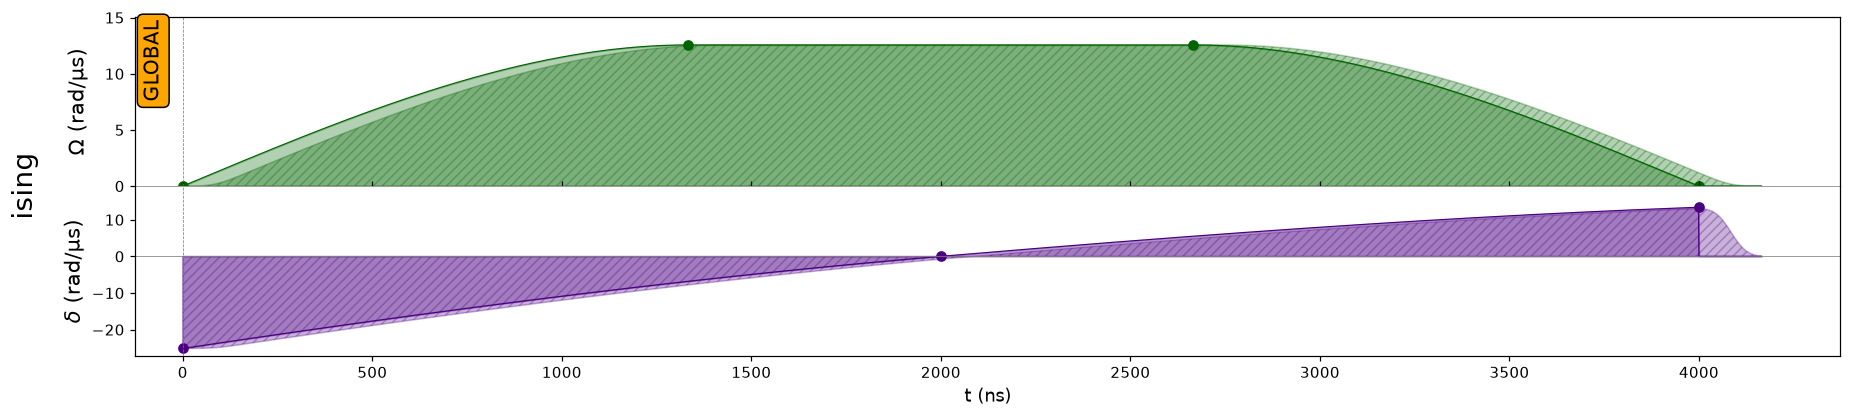

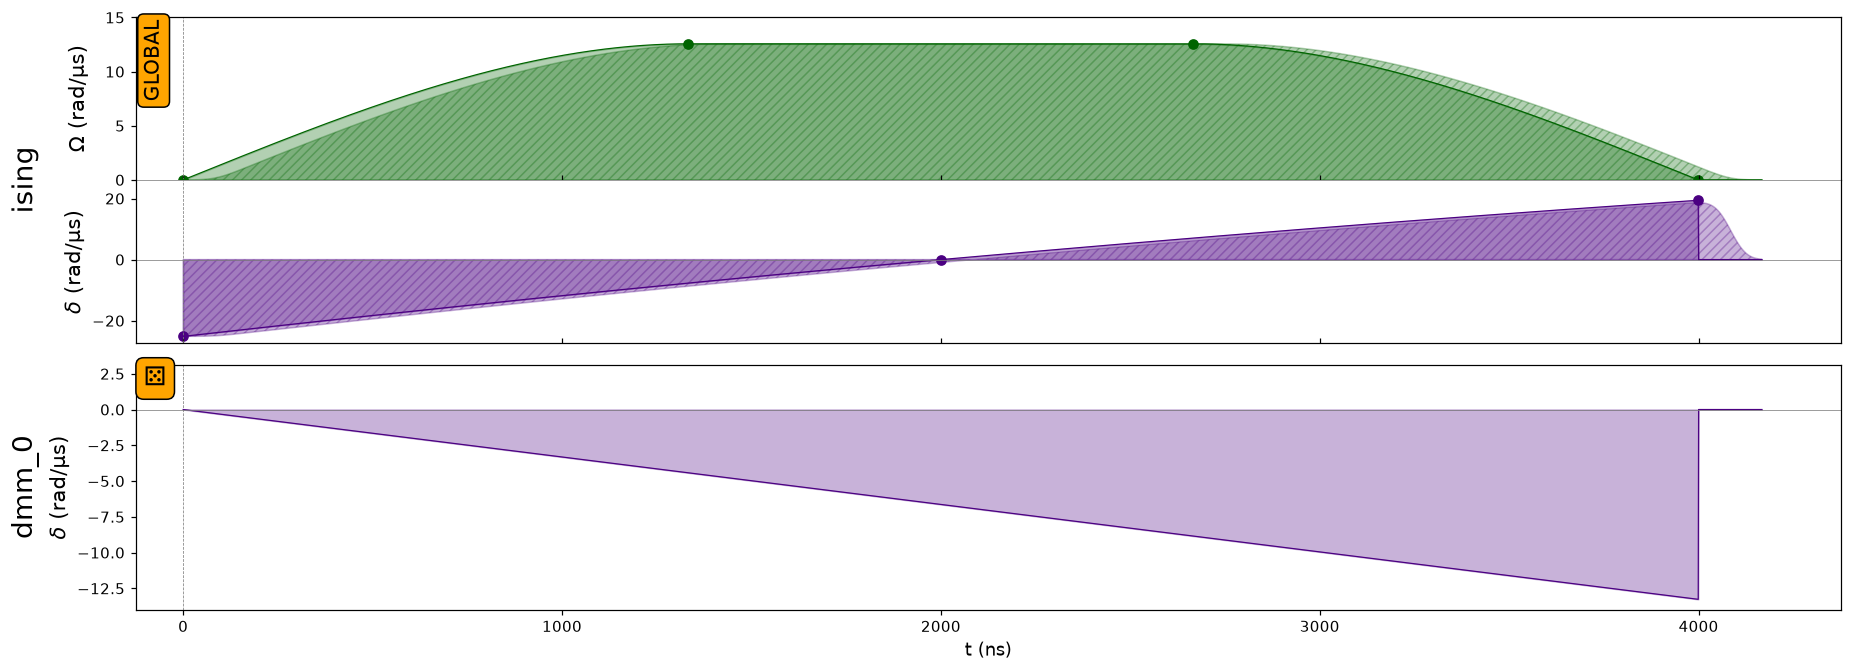

In [12]:
T_NS = 4000
SHOTS = 2000
DELTA_0 = -2 * OMEGA_MAX


def build_sequence(use_dmm):
    traps = [p for p in pos]                    # add n empty traps, >= r_min from everything, inside R_max
    for p in (np.array([r * np.cos(t), r * np.sin(t)]) for r in np.arange(R_MAX - 1, 0, -6)
              for t in np.linspace(0, 2 * np.pi, 48, endpoint=False)):
        if len(traps) == 2 * n:
            break
        if np.linalg.norm(np.array(traps) - p, axis=1).min() >= R_MIN + 0.1:
            traps.append(p)
    layout = RegisterLayout(np.array(traps))
    # RegisterLayout re-sorts its traps, so look ours up by coordinate to keep atom m = variable m
    reg = layout.define_register(*layout.get_traps_from_coordinates(*pos), qubit_ids=[f"q{m}" for m in range(n)])
    assert np.allclose(np.array([reg.qubits[f"q{m}"].as_array() for m in range(n)]), pos, atol=1e-5)
    device = dataclasses.replace(DEVICE.to_virtual(), dmm_objects=MockDevice.dmm_objects) if use_dmm else DEVICE
    seq = Sequence(reg, device)
    seq.declare_channel("ising", "rydberg_global")
    delta_f = delta_dmm_top if use_dmm else delta_glob
    amp = InterpolatedWaveform(T_NS, [1e-9, OMEGA_MAX, OMEGA_MAX, 1e-9])
    det = InterpolatedWaveform(T_NS, [DELTA_0, 0, delta_f])
    seq.add(Pulse(amp, det, 0), "ising")
    if use_dmm:
        dmap = reg.define_detuning_map({f"q{m}": float(eps[m]) for m in range(n)})
        seq.config_detuning_map(dmap, "dmm_0")
        seq.add_dmm_detuning(RampWaveform(T_NS, 0, delta_dmm), "dmm_0")
    return seq


seqs = {"global": build_sequence(False), "global+DMM": build_sequence(True)}
seqs["global"].draw()
seqs["global+DMM"].draw()

In [13]:
RUNS = {   # name: (sequence, interaction-matrix override, the final classical energy this run should minimise)
    "global": (seqs["global"], None, (h_glob, U / alpha)),
    "global+DMM": (seqs["global+DMM"], None, (h_dmm, U / alpha)),
    "ideal J + DMM": (seqs["global+DMM"], alpha * J, (h, J)),
}
counts = {}
for name, (seq, U_override, (h_v, J_v)) in RUNS.items():
    cfg = emu_sv.SVConfig(observables=[emu_sv.BitStrings(evaluation_times=[1.0], num_shots=SHOTS)],
                          interaction_matrix=U_override, log_level=40)
    torch.manual_seed(SEED)                     # emu-sv samples shots with torch: seed for reproducible counts
    result = emu_sv.SVBackend(seq, config=cfg).run()
    counts[name] = Counter(result.get_result("bitstrings", 1.0))
    E_own = energies(Z, h_v, J_v)
    gs_bits = "".join(map(str, Z[np.argmin(E_own)]))
    print(f"{name:14s}: {len(counts[name]):4d} distinct bitstrings; "
          f"P(shot = ground state of its own final Hamiltonian) = {counts[name][gs_bits] / SHOTS:.3f}")

rng_rand = np.random.default_rng(1)
counts["uniform random"] = Counter("".join(map(str, z)) for z in rng_rand.integers(0, 2, size=(SHOTS, n)))

global        :   81 distinct bitstrings; P(shot = ground state of its own final Hamiltonian) = 0.387


global+DMM    :  415 distinct bitstrings; P(shot = ground state of its own final Hamiltonian) = 0.036


ideal J + DMM : 1528 distinct bitstrings; P(shot = ground state of its own final Hamiltonian) = 0.001


## 6. Decode and score (brief §9.4)

Decoding rule (stated up front, Pitfall 9.1): **drop the slack bits**, require C1 (each customer on exactly one
truck) and C2 (load ≤ Q, recomputed from x) — no classical repair. We report the best *feasible* shot.
"Reached reference" means gap ≤ ε = 0, i.e. the shot's clustering is one of the optimal clusterings (as sets of groups).

In [14]:
EPS_GAP = 0.0


def score(counter):
    shots = sum(counter.values())
    n_c1 = n_feas = n_ref = n_slack_exact = 0
    best_f, best_assign = np.inf, None
    for bits, cnt in counter.items():
        z = np.array([int(b) for b in bits])
        assign, ok1, ok2 = decode(z)
        n_c1 += cnt * ok1
        if not (ok1 and ok2):
            continue
        n_feas += cnt
        f_val = cluster_cost(assign, c)
        n_slack_exact += cnt * bool(np.isclose(energies(z[None], h, J)[0] + const, f_val))
        n_ref += cnt * ((f_val - f_star) / f_star * 100 <= EPS_GAP + 1e-9)
        if f_val < best_f:
            best_f, best_assign = f_val, assign
    return {
        "atoms": n,
        "C1 rate": n_c1 / shots,
        "feasibility rate": n_feas / shots,
        "slack-exact rate": n_slack_exact / shots,
        "P(reach ref)": n_ref / shots,
        "best feasible f": best_f,
        "model gap %": (best_f - f_star) / f_star * 100 if best_assign is not None else np.nan,
        "_assign": best_assign,
    }


scores = {name: score(cnt) for name, cnt in counts.items()}
cols_ = ["atoms", "C1 rate", "feasibility rate", "slack-exact rate", "P(reach ref)", "best feasible f", "model gap %"]
print(f"{'method':16s}" + "".join(f"{k:>18s}" for k in cols_))
for name, s in scores.items():
    print(f"{name:16s}" + "".join(f"{s[k]:18.3f}" if isinstance(s[k], float) else f"{s[k]:18d}" for k in cols_))
print(f"\nreference: C* = {f_star:.2f}, proven optimum (brute force over {K ** N} assignments)")
print(f"embedding fidelity: couplings {emb_err:.1%}; linear terms global "
      f"{np.linalg.norm(h_glob - h) / np.linalg.norm(h):.1%}, DMM {np.linalg.norm(h_dmm - h) / np.linalg.norm(h):.1e}")

method                       atoms           C1 rate  feasibility rate  slack-exact rate      P(reach ref)   best feasible f       model gap %
global                          14             0.001             0.001             0.000             0.000           111.064             0.959
global+DMM                      14             0.095             0.086             0.003             0.003           110.009             0.000
ideal J + DMM                   14             0.064             0.052             0.002             0.018           110.009             0.000
uniform random                  14             0.061             0.033             0.001             0.007           110.009             0.000

reference: C* = 110.01, proven optimum (brute force over 16 assignments)
embedding fidelity: couplings 48.8%; linear terms global 37.7%, DMM 1.1e-16


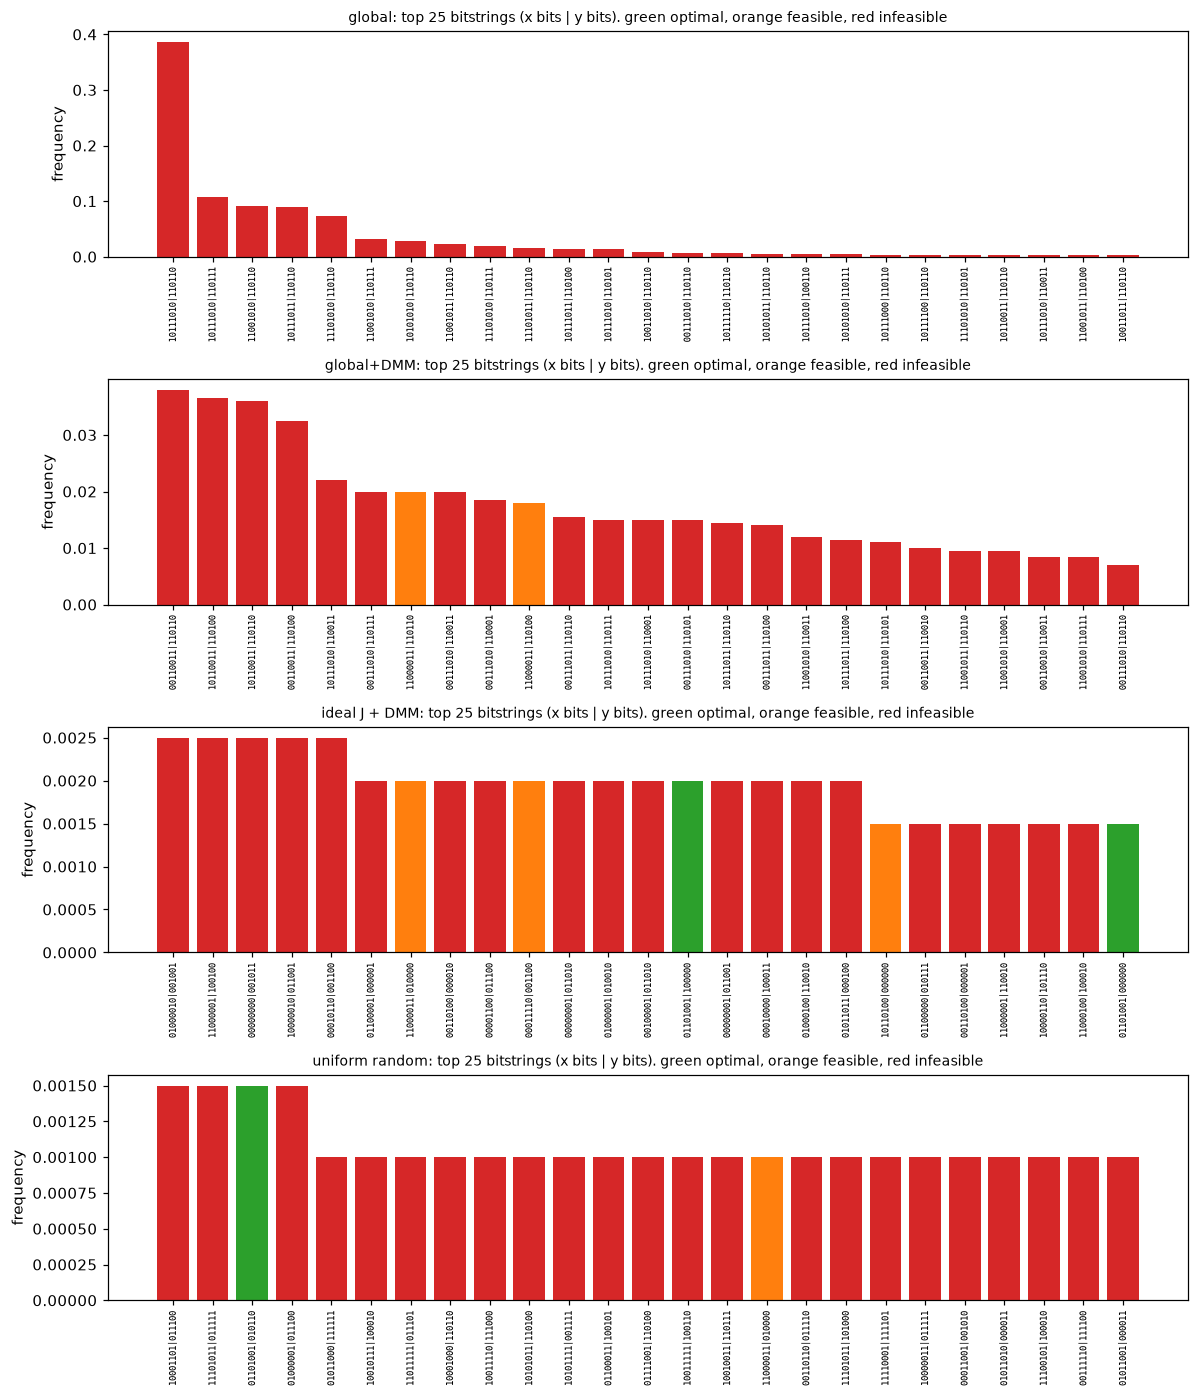

In [15]:
fig, axes = plt.subplots(len(counts), 1, figsize=(11, 3.2 * len(counts)))
for ax, (name, cnt) in zip(axes, counts.items()):
    top_ = cnt.most_common(25)
    colors_ = []
    for bits, _ in top_:
        a_, ok1, ok2 = decode(np.array([int(b) for b in bits]))
        colors_.append("tab:green" if ok1 and ok2 and canon(a_) in opt_clusterings
                       else "tab:orange" if ok1 and ok2 else "tab:red")
    ax.bar(range(len(top_)), [v / SHOTS for _, v in top_], color=colors_)
    ax.set_xticks(range(len(top_)), [b[:n_x] + "|" + b[n_x:] for b, _ in top_], rotation=90, fontsize=6,
                  family="monospace")
    ax.set_ylabel("frequency")
    ax.set_title(f"{name}: top 25 bitstrings (x bits | y bits). green optimal, orange feasible, red infeasible",
                 fontsize=9)
plt.tight_layout(); plt.show()

## 7. Close the loop: route each cluster, CVRP gap

Clusters on tier S have ≤ 3 customers (trivial in the brief's sense), so each is routed exactly by enumerating tours
from the depot. The CVRP reference is brute force over every feasible assignment × exact routing.

CVRP reference C* = 260.04 (proven optimum)
decomposition gap (model optimum routed exactly) = 7.2%


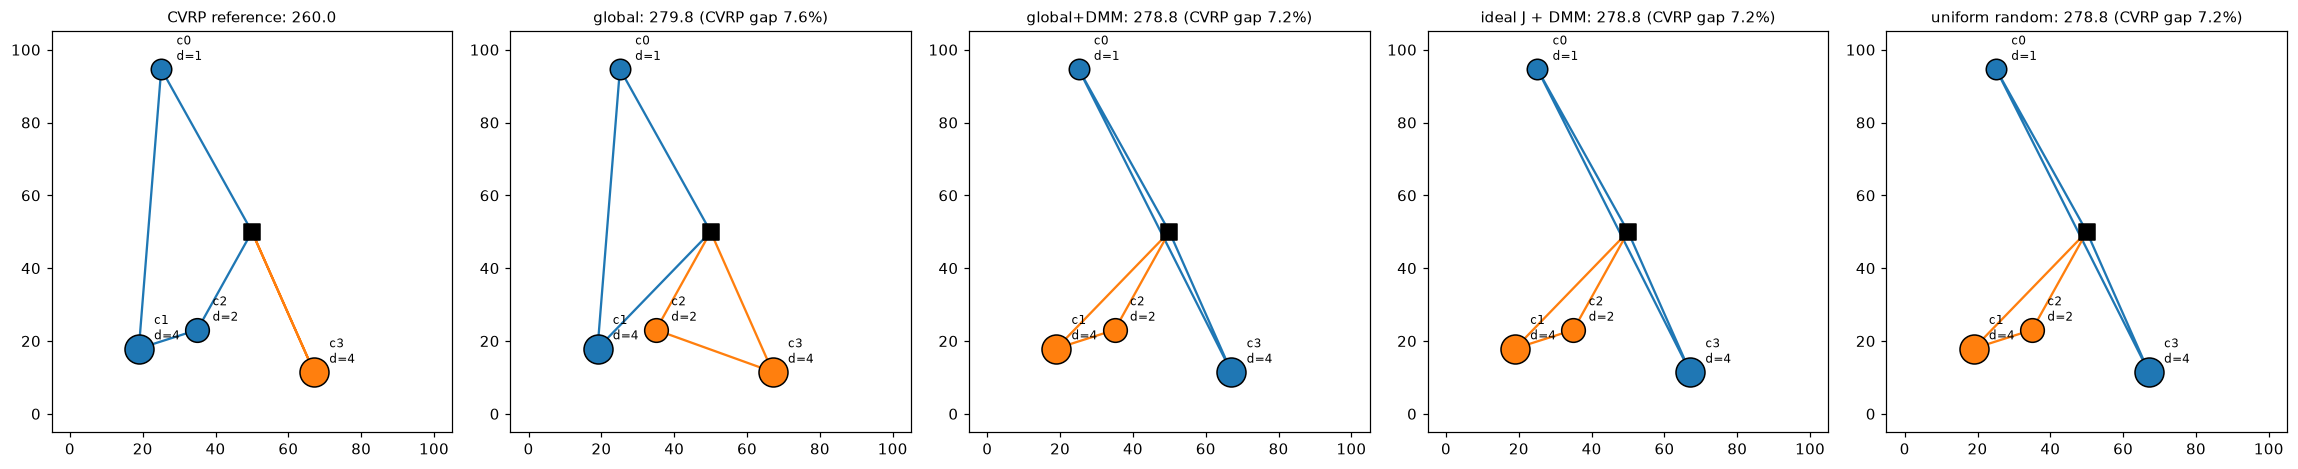

In [16]:
def tour_len(route):
    if len(route) == 0:
        return 0.0
    path = np.vstack([DEPOT, xy[list(route)], DEPOT])
    return float(np.linalg.norm(np.diff(path, axis=0), axis=1).sum())


def best_route(members):
    if len(members) == 0:
        return (), 0.0
    return min(((p, tour_len(p)) for p in itertools.permutations(members)), key=lambda t: t[1])


def route_assignment(assign):
    routes = [best_route(np.flatnonzero(assign == k).tolist()) for k in range(K)]
    return [r for r, _ in routes], sum(l for _, l in routes)


cvrp_costs = [route_assignment(a)[1] if ok else np.inf for a, ok in zip(ASSIGN, FEAS_ALL)]
cvrp_ref = min(cvrp_costs)
cvrp_ref_assign = ASSIGN[int(np.argmin(cvrp_costs))]
decomp_cost = route_assignment(x_star_assign)[1]
print(f"CVRP reference C* = {cvrp_ref:.2f} (proven optimum)")
print(f"decomposition gap (model optimum routed exactly) = {(decomp_cost - cvrp_ref) / cvrp_ref:.1%}")
fig, axes = plt.subplots(1, len(scores) + 1, figsize=(4.2 * (len(scores) + 1), 4.2))
r_ref, _ = route_assignment(cvrp_ref_assign)
draw_clusters(axes[0], cvrp_ref_assign, f"CVRP reference: {cvrp_ref:.1f}", r_ref)
for ax, (name, s) in zip(axes[1:], scores.items()):
    if s["_assign"] is None:
        ax.set_title(f"{name}: no feasible shot", fontsize=9); ax.axis("off")
        continue
    routes, cost = route_assignment(s["_assign"])
    s["CVRP gap %"] = (cost - cvrp_ref) / cvrp_ref * 100
    draw_clusters(ax, s["_assign"], f"{name}: {cost:.1f} (CVRP gap {s['CVRP gap %']:.1f}%)", routes)
plt.tight_layout(); plt.show()

## 8. Variable accounting (Derive 4.1)

In [17]:
print(f"{'tier':5s}{'N':>4s}{'K':>4s}{'Q':>5s}{'NK':>6s}{'K*B':>6s}{'total':>7s}  fits 80?")
for tier, (N_, K_, Q_) in {"S": (4, 2, 7), "M": (10, 3, 20), "L": (15, 4, 30)}.items():
    B_ = int(np.ceil(np.log2(Q_ + 1)))
    tot = N_ * K_ + K_ * B_
    print(f"{tier:5s}{N_:4d}{K_:4d}{Q_:5d}{N_ * K_:6d}{K_ * B_:6d}{tot:7d}  {'yes' if tot < 80 else 'at cap' if tot == 80 else 'no'}")

tier    N   K    Q    NK   K*B  total  fits 80?
S       4   2    7     8     6     14  yes
M      10   3   20    30    15     45  yes
L      15   4   30    60    20     80  at cap


## Reading the results

Where each stage stands, in pipeline order (numbers above are from this seed; rerun to see them change):

1. **Formulation is correct.** The slack QUBO's brute-force ground state is the constrained optimum, with the
   rigorous weight A = W = f(certificate) + 1. Only 8 of the 16 384 bitstrings are "feasible with exact slack".
2. **Embedding is where it breaks.** Per truck, 7 atoms (4 customers + 3 slack bits) want to be mutually coupled
   with strengths spanning ~10×, while each customer's two copies (one per truck) want a 2A coupling and unrelated
   atoms want none. In 2D the fit keeps the big same-truck couplings and sacrifices the C1 (same customer) pairs:
   on seed 12 they come out ~600× too weak (0.0016 vs 0.95 rad/μs), so nothing stops a customer riding both trucks. The embedded energy's ground state is then infeasible even with exact
   DMM linear terms, so a perfect adiabatic sweep would still return a wrong answer.
3. **Global detuning alone cannot express slack's linear terms** (37.7 % error): x and y bits need different
   rewards. The DMM fixes this exactly, but only in emulation.
4. **Even a perfect embedding does not save it within 6 μs.** The "ideal J + DMM" diagnostic gives the sweep the
   exact QUBO couplings. Its shots barely beat uniform random, because once the penalties fit the device range,
   the objective difference between the best and second-best clustering is ~0.003 rad/μs, against Ω_max = 12.6.
   That is the dynamic-range cost of slack, measured.

These are the numbers an improved formulation has to beat: 14 atoms, feasibility rate, P(reach ref), and the
coupling/linear embedding errors.